In [32]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import numpy as np
import time
import os
import contextily as ctx

**Problématique** : dans quelle mesure l'exposition locale aux activités industrielles (ICPE) amplifie-t-elle la vulnérabilité et la baisse de niveau des nappes phréatiques ?

## Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [33]:
#On crée le dossier data qui va stocker toutes nos données :
os.makedirs("../../data", exist_ok=True)

#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"

lien_stockage_physique_icpe = "../../data/icpe.csv"

#Si le fichier a déjà été téléchargé, on réutilise la copie locale (le téléchargement est long)
if os.path.exists(lien_stockage_physique_icpe):
    print("Fichier ICPE déjà téléchargé, on réutilise la copie locale.")
else:
    fichier_icpe = rq.get(url_icpe)

    if fichier_icpe.status_code == 200:
        with open(lien_stockage_physique_icpe, "wb") as f:
            f.write(fichier_icpe.content)
        print("Fichier téléchargé.")
    else:
        print("Erreur avec le téléchargement du fichier ICPE.")

Fichier ICPE déjà téléchargé, on réutilise la copie locale.


On a  136244 installations industrielles. Dont  104742 installations industrielles ICPE.
On ne garde que les  43739 installations industrielles pures.


Text(0, 0.5, "Nombre d'installations industrielles")

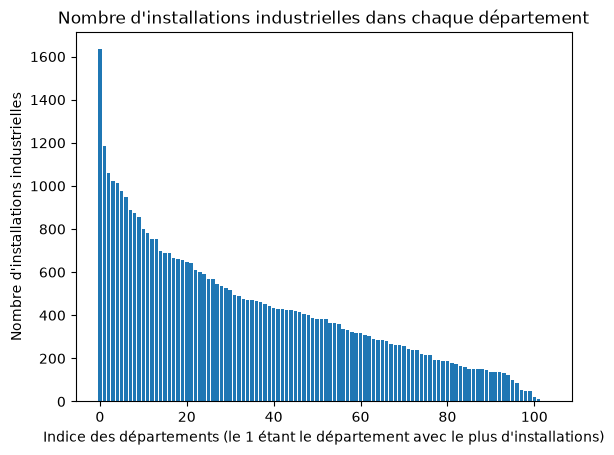

In [34]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)
plt.title("Nombre d'installations industrielles dans chaque département")
plt.xlabel("Indice des départements (le 1 étant le département avec le plus d'installations)")
plt.ylabel("Nombre d'installations industrielles")

On prend par défaut le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  
La liste `DEPARTEMENTS` ci-dessous permet d'en étudier plusieurs à la fois : toute la suite du notebook s'applique à tous les départements de la liste,
et chaque département n'est téléchargé qu'une fois (fichiers `data/..._<département>.csv`).

In [35]:
#Départements étudiés : par défaut celui qui a le plus d'ICPE (le 59)
#Pour en étudier plusieurs, il suffit de compléter la liste, par exemple : DEPARTEMENTS = ["59", "88", "68"]
DEPARTEMENTS = [str(classement_dpt.index[0])]
print("Départements analysés : ", DEPARTEMENTS)

Départements analysés :  ['59']


Mise en forme des données géographiques avec Geopandas

In [36]:
installations_indust = installations_indust.loc[installations_indust["num_dep"].isin(DEPARTEMENTS)]

#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles des départements étudiés
nb_position_less = installations_indust.loc[installations_indust["x"].isnull() | installations_indust["y"].isnull() | installations_indust["code_epsg"].isnull()].shape[0]
print(nb_position_less, "installations industrielles n'ont pas de coordonnées géographiques.")
installations_indust = installations_indust.loc[installations_indust["x"].notnull() & installations_indust["y"].notnull() & installations_indust["code_epsg"].notnull()]

#On utilise les coordonnées des installations pour les localiser avec Geopandas
installations_indust["geometry"] = None #Colonne qui va prendre la valeur position Geopandas
codes_epsg_type_coord = installations_indust["code_epsg"].unique()   #On veut que ça marche pour les différents types de référentiels (x,y)
for epsg in codes_epsg_type_coord:
    filtre = installations_indust["code_epsg"] == epsg
    points = gpd.points_from_xy(
        installations_indust.loc[filtre, "x"], 
        installations_indust.loc[filtre, "y"]
    )
    serie_geometrique = gpd.GeoSeries(points, crs=f"EPSG:{int(epsg)}")
    serie_geometrique = serie_geometrique.to_crs("EPSG:2154") #On ramène tout sous le même format
    installations_indust.loc[filtre, "geometry"] = serie_geometrique.values

#On définit un GeoDataFrame pour les études géométriques :
installations_indust = gpd.GeoDataFrame(installations_indust, geometry="geometry", crs="EPSG:2154")

0 installations industrielles n'ont pas de coordonnées géographiques.


### Récupération des données sur les nappes phréatiques des départements étudiés

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.  
Encore moins toutes les chroniques d'un coup.  
Donc on sélectionne que les départements étudiés (par défaut le 59, où l'on a vu qu'il y avait une grande concentration d'industrie).

In [37]:
import ast

morceaux = []
for dep in DEPARTEMENTS:
    lien_stations = f"../../data/stations_nappes_{dep}.csv"   #Un fichier en cache par département
    if not os.path.exists(lien_stations):
        #On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
        url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
        params = {"code_departement": dep, "size": 5000, "format": "json"}
        fichier_stations = rq.get(url_stations, params=params)

        if fichier_stations.status_code == 200:
            pd.DataFrame(fichier_stations.json()["data"]).to_csv(lien_stations, encoding='utf-8')
            print("Stations du département", dep, "téléchargées.")
        else:
            print(fichier_stations.status_code)
            print("Erreur avec le téléchargement du fichier stations Hubeau.")
    morceaux.append(pd.read_csv(lien_stations, index_col=0).assign(departement=dep))   #On garde le département étudié de chaque station
stations = pd.concat(morceaux, ignore_index=True)

#Dans le CSV, les listes (masses d'eau, entités BD LISA) sont stockées en texte : on les reconvertit en listes
for colonne in ["codes_bdlisa", "urns_bdlisa", "codes_masse_eau_edl", "noms_masse_eau_edl", "urns_masse_eau_edl"]:
    stations[colonne] = stations[colonne].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else v)
print("On a ", stations.shape[0], "stations de mesure des nappes phréatiques dans les départements ", DEPARTEMENTS, ".")

On a  730 stations de mesure des nappes phréatiques dans les départements  ['59'] .


Mise en forme des données géographiques avec Geopandas

In [38]:
#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles des départements étudiés
nb_position_less = stations.loc[stations["x"].isnull() | stations["y"].isnull()].shape[0]
print(nb_position_less, "stations n'ont pas de coordonnées géographiques.")
stations = stations.loc[stations["x"].notnull() & stations["y"].notnull()]

#On crée le modèle Geopandas
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations['x'], stations['y']),
    crs="EPSG:4326"
).to_crs(epsg=2154) #On ramène tout sous le même format que les installations industrielles

0 stations n'ont pas de coordonnées géographiques.


Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques entre janvier 2015 et janvier 2026

In [39]:
#On ne peut pas récupérer les mesures des nappes phréatiques pour toutes les stations en même temps.
#Quand on essaye de récupérer toutes les données de toutes les nappes, on a une erreur 414 : la requête URL est trop longue avec tous les code_bss en paramètres.
#Et Hub'eau refuse d'aller au-delà de 20 000 lignes par requête (page x taille de page <= 20 000) : avec plus, il répond une erreur 400.
#Donc on demande les stations par petits paquets, et on recoupe un paquet trop gros en deux (puis la période en deux pour une seule station).
url_chroniques_api = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"

def requete_hubeau(params, url=url_chroniques_api):
    """Une requête Hub'eau, réessayée en cas de coupure ou de serveur saturé (mais pas en cas de requête refusée)."""
    for essai in range(10):
        try:
            reponse = rq.get(url, params=params, timeout=180)
        except Exception as e:
            print("Erreur requête :", e, "- pas grave, on va réessayer.")
            time.sleep(2)
            continue
        if reponse.status_code in (200, 206) and reponse.headers.get("content-type", "").startswith("application/json"):
            return reponse.json()
        if 400 <= reponse.status_code < 500 and reponse.status_code != 429:   #Requête refusée : réessayer ne servirait à rien
            raise RuntimeError(f"Hub'eau a refusé la requête ({reponse.status_code}) : {reponse.text[:200]}")
        time.sleep(2 * (essai + 1))   #Serveur saturé : on attend un peu plus à chaque fois
    raise RuntimeError("Hub'eau ne répond pas.")

def telecharger_paquet(paquet, debut="2015-01-01", fin="2026-01-01"):
    data = requete_hubeau({"code_bss": ",".join(paquet), "size": 20000, "format": "json", "date_debut_mesure": debut, "date_fin_mesure": fin})
    if data["count"] <= 20000:   #Tout tient dans une seule page
        return data["data"]
    if len(paquet) > 1:   #Trop de lignes : on coupe le paquet de stations en deux
        return telecharger_paquet(paquet[:len(paquet) // 2], debut, fin) + telecharger_paquet(paquet[len(paquet) // 2:], debut, fin)
    milieu = str(pd.Timestamp(debut) + (pd.Timestamp(fin) - pd.Timestamp(debut)) / 2)[:10]   #Une seule station : on coupe la période en deux
    return telecharger_paquet(paquet, debut, milieu) + telecharger_paquet(paquet, milieu, fin)

def telecharger_chroniques(liste_codes_bss_stations):
    chroniques = []
    for i in range(0, len(liste_codes_bss_stations), 5):   #Paquets de 5 stations : environ 4 000 mesures par station sur 11 ans
        chroniques.extend(telecharger_paquet(liste_codes_bss_stations[i:i+5]))
        print("Stations téléchargées :", min(i + 5, len(liste_codes_bss_stations)), "sur", len(liste_codes_bss_stations))
    #Les deux moitiés d'une période coupée en deux partagent leur jour de coupure : on enlève ces doublons
    return pd.DataFrame(chroniques).drop_duplicates(subset=["code_bss", "date_mesure", "timestamp_mesure"])


morceaux = []
for dep in DEPARTEMENTS:
    lien_chroniques = f"../../data/chroniques_nappes_{dep}.csv"   #Un fichier en cache par département
    if not os.path.exists(lien_chroniques):
        #On ne télécharge que les stations qui peuvent être mesurées au moins 80 % des mois de 2015-2025 (critère de la partie 2) :
        #début des mesures au plus tard en mars 2017 et fin au plus tôt en octobre 2023. Les autres seraient écartées de toute façon.
        utiles = stations.loc[(stations["departement"] == dep) & (stations["date_debut_mesure"] <= "2017-03-31") & (stations["date_fin_mesure"] >= "2023-10-01")]
        telecharger_chroniques(utiles["code_bss"].tolist()).to_csv(lien_chroniques, encoding='utf-8')
        print("Chroniques du département", dep, "téléchargées.")
    morceaux.append(pd.read_csv(lien_chroniques, index_col=0))
chroniques = pd.concat(morceaux, ignore_index=True)
print("Chroniques chargées :", chroniques.shape[0], "mesures.")

Chroniques chargées : 140251 mesures.


On nettoie les données des séries temporelles des nappes phréatiques

In [40]:
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
print("Nombre de chroniques sans niveau d'eau : ", chroniques.loc[chroniques["niveau_nappe_eau"].isnull()].shape[0])
#On supprime les chroniques pour lesquelles le niveau d'eau est NULL
chroniques = chroniques.loc[chroniques["niveau_nappe_eau"].notnull()]

Nombre de chroniques sans niveau d'eau :  0


## Test des données

Un exemple de série temporelle pour une station (nappe phréatique)

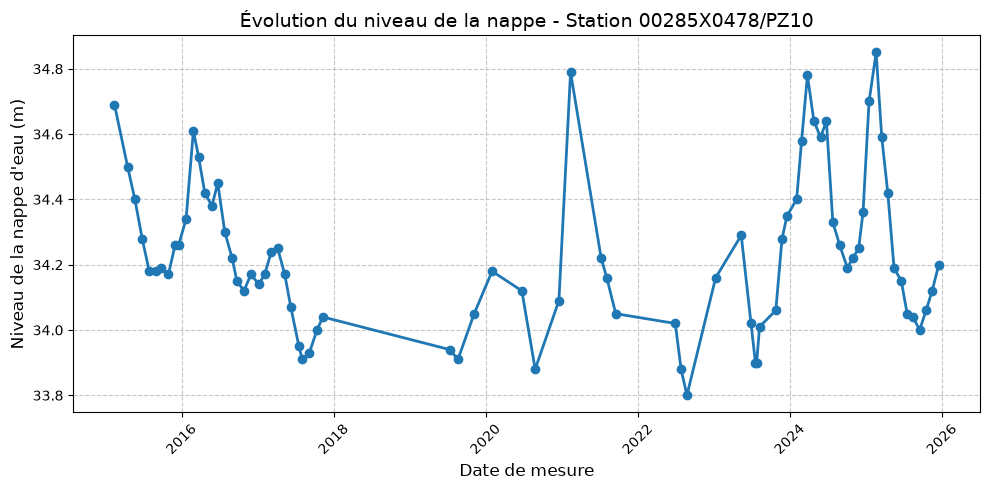

In [41]:
# Représentation d'une série temporelle d'une station
station_cible = '00285X0478/PZ10'
df_station = chroniques[chroniques['code_bss'] == station_cible]
df_station = df_station.sort_values(by='date_mesure')

plt.figure(figsize=(10, 5))
plt.plot(
    df_station['date_mesure'], 
    df_station['niveau_nappe_eau'], 
    marker='o',         # Ajoute un point sur chaque mesure réelle
    linestyle='-',      # Relie les points par une ligne
    color='#1f77b4', 
    linewidth=2
)

plt.title(f"Évolution du niveau de la nappe - Station {station_cible}", fontsize=14)
plt.xlabel("Date de mesure", fontsize=12)
plt.ylabel("Niveau de la nappe d'eau (m)", fontsize=12)
plt.xticks(rotation=45) # Penche les dates pour éviter qu'elles ne se superposent
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Nettoyage et standardisation des données

Les séries temporelles de Hub'eau donnent des mesures des nappes phréatiques à des dates différentes entre les stations.  
Pour les calculs futurs, on va standardiser ça en faisant une moyenne par station et par mois

In [42]:
chroniques['date_mois_annee'] = chroniques['date_mesure'].dt.to_period('M')
chroniques

chroniques_niveau_mensuel = (chroniques.groupby(["code_bss", "date_mois_annee"])
              .agg({
                  "niveau_nappe_eau":"mean",
                  "profondeur_nappe":"mean"
              })
              .reset_index()
    )
chroniques_niveau_mensuel["date_mesure"] = chroniques_niveau_mensuel["date_mois_annee"].dt.to_timestamp()
chroniques_niveau_mensuel['date_mesure'] = pd.to_datetime(chroniques_niveau_mensuel['date_mesure'])
print("Les données ont été normalisées en moyenne par mois pour chaque station.")

Les données ont été normalisées en moyenne par mois pour chaque station.


# 1. Répartition des usines et des stations hydrologiques dans les départements étudiés

Text(0.5, 1.0, 'Répartition des usines ICPE et des stations hydrologiques dans les départements étudiés')

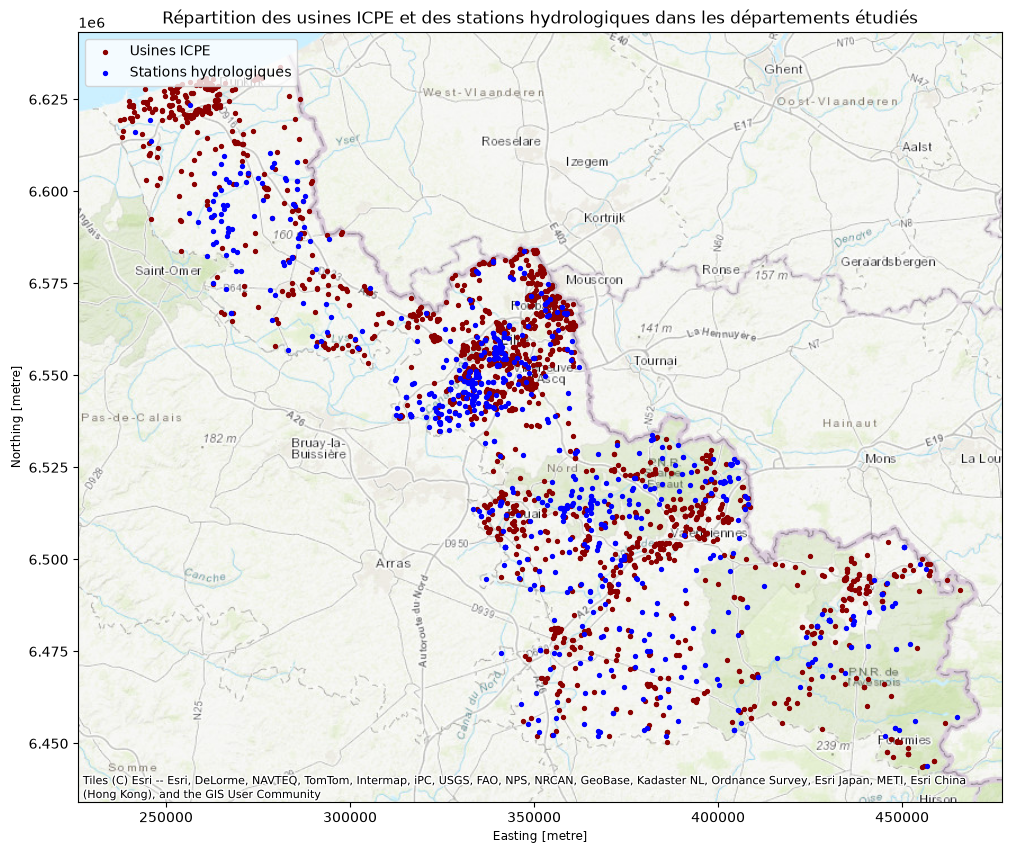

In [43]:
# Stations (points bleus, taille réduite, avec un fin contour blanc pour la lisibilité)
ax = plt.subplots(figsize=(12, 10))[1]
installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
plt.legend(loc="upper left")
plt.title("Répartition des usines ICPE et des stations hydrologiques dans les départements étudiés")

## On cherche la quantité d'usines par station

In [44]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon['geometry'] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby('code_bss').size().reset_index(name='nb_usines_5km')

stations = stations.merge(nb_usine_ds_rayon, on='code_bss', how='left')
stations['nb_usines_5km'] = stations['nb_usines_5km'].fillna(0).astype(int) #On remplace les valeurs nulles par 0

## On relie chaque usine à sa station la plus proche

In [45]:
#On associe chaque usine à la station la plus proche (si elle est à moins de 5km)
usines_station = gpd.sjoin_nearest(installations_indust, stations[['code_bss', 'geometry']], how="left", max_distance=r, distance_col="distance_station")
usines_station = usines_station.drop_duplicates(subset='code_aiot')  #Plusieurs stations peuvent être au même endroit, on n'en garde qu'une
usines_station = usines_station.drop(columns='index_right')
print(usines_station['code_bss'].notnull().sum(), "usines sur ", usines_station.shape[0], "ont une station à moins de 5km.")

1578 usines sur  1633 ont une station à moins de 5km.


## On relie chaque nappe aux usines qui sont à moins de 5km d'une de ses stations

In [46]:
#Une station peut mesurer plusieurs nappes : on fait une ligne par couple (usine, nappe)
usines_nappes = usines_ds_rayon[['code_aiot', 'nom_ets', 'codes_masse_eau_edl', 'noms_masse_eau_edl']].explode(['codes_masse_eau_edl', 'noms_masse_eau_edl'])
usines_nappes = usines_nappes.rename(columns={'codes_masse_eau_edl': 'code_nappe', 'noms_masse_eau_edl': 'nom_nappe'})
usines_nappes = usines_nappes.dropna(subset=['code_nappe'])  #On enlève les stations sans nappe
usines_nappes = usines_nappes.drop_duplicates(subset=['code_nappe', 'code_aiot'])  #Une usine proche de 2 stations d'une même nappe ne compte qu'une fois

#Pour chaque nappe, la liste des usines à moins de 5km d'une de ses stations
nappes_usines = usines_nappes.groupby(['code_nappe', 'nom_nappe']).agg(nb_usines=('code_aiot', 'size'), usines=('nom_ets', list)).reset_index()
nappes_usines = nappes_usines.sort_values('nb_usines', ascending=False)
print("On a ", nappes_usines.shape[0], "nappes reliées à au moins une usine.")
nappes_usines

On a  11 nappes reliées à au moins une usine.


,code_nappe,nom_nappe,nb_usines,usines
7,AG315,Calcaire carbonifère de Roubaix-Tourcoing,588,"[Ports de Lille (bat 2 et 4), DALKIA ( Chauffe..."
6,AG314,Sables du Landénien des Flandres,577,"[TIM, Grand Port Maritime de Dunkerque (GMPD),..."
0,AG303,Craie de la vallée de la Deûle,514,"[Ports de Lille (bat 2 et 4), THORNHILL Servic..."
2,AG306,Craie des vallées de la Scarpe et de la Sensée,402,"[EPC - FRANCE, HANOT Jean-Marc, Ports de Lille..."
4,AG310,Craie du Cambrésis,230,"[TRITUBE, LE COMPTOIR DE LA FESTIVITE, SOCIETE..."
3,AG307,Craie du Valenciennois,193,"[HANOT Jean-Marc, NORZINCO, SUEZ RV NORD EST, ..."
8,AG318,Sables du Landénien d'Orchies,189,"[EPC - FRANCE, HANOT Jean-Marc, NORZINCO, SUEZ..."
9,B2G316,Calcaires de l'Avesnois,118,"[SCREG Nord Picardie S.A, NEXANS France, VALL..."
10,HG508,Socle ardennais,9,"[AUTO PIECES PIENNES, CHAUDRONNERIE D'ANOR, PA..."
1,AG304,Craie de l'Artois et de la vallée de la Lys,6,"[BAUDELET HOLDING (VALO PARC), MPP BOUTONS, BA..."


# 2. Partie climat : retirer l'effet de la pluie

Le niveau d'une nappe monte quand il pleut plus que ce que le sol et la végétation évaporent, et baisse sinon.
Pour juger l'effet de l'industrie *toutes choses égales par ailleurs*, on retire d'abord cette part climatique :
ce qui reste, le **résidu**, contient les tendances que le climat n'explique pas.

## 2.1 Pluie efficace SAFRAN

Météo-France publie en open data la réanalyse **SAFRAN (SIM2)** : une valeur par jour sur une grille de 8 km.
On garde la **pluie efficace** `PE` (pluie moins évaporation, en mm) de la maille la plus proche de chaque station.
On remonte à 2012 : une nappe peut réagir à la pluie des trois années précédentes.

In [47]:
URL_SAFRAN = "https://meteofrance.s3.sbg.io.cloud.ovh.net/data/REF_CC/SIM/QUOT_SIM2_{}.csv.gz"   #Les {} seront remplacées par l'année
def lien_pluie(dep):
    return f"../../data/pluie_efficace_stations_{dep}.csv.gz"   #Cache par département : une ligne par station et par mois
deps_a_telecharger = [dep for dep in DEPARTEMENTS if not os.path.exists(lien_pluie(dep))]

#SAFRAN est en Lambert II étendu (EPSG:27572), avec des coordonnées en hectomètres (x 100 pour repasser en mètres)
stations_lambert2 = (stations.loc[stations["departement"].isin(deps_a_telecharger)]   #Seulement les stations sans cache
                     .drop_duplicates(subset="code_bss")
                     .set_index("code_bss")
                     .to_crs(epsg=27572)
                     [["geometry"]])   #Doubles crochets : on garde un GeoDataFrame (et pas une simple série de points), sjoin_nearest en a besoin


#Téléchargement, seulement la première fois pour chaque département (environ 2 Go, tous les nouveaux départements d'un coup) : ensuite on relit les fichiers locaux
if deps_a_telecharger:
    # Code légèrement sous optimal pour une question de facilité de lecture du code et de compréhension : on telecharge 2 fois 2012 mais c'est minime
    # On prend le fichier des pluies et on extrait la grille, ensuite on fait l'appariement avec les stations de la partie précédente et 
    # enfin on garde seulement les mailles utiles. Après on fait des jointures entre les mailles utiles calculées qui nous intéresse et les pluies


    #Chaque maille apparaît une fois par jour dans le fichier, on ne garde que la liste des mailles
    grille = (pd
              .read_csv(URL_SAFRAN.format(2012), sep=";", usecols=["LAMBX", "LAMBY"])
              .rename(columns={"LAMBX": "X", "LAMBY": "Y"})
              .drop_duplicates())
    
    #Type nécessaire pour faire le sjoin_nearest et passage des hm en m
    grille = gpd.GeoDataFrame(grille, geometry=gpd.points_from_xy(grille["X"] * 100, grille["Y"] * 100), crs="EPSG:27572")
    
    appariement = gpd.sjoin_nearest(stations_lambert2, grille, distance_col="distance")

    appariement = appariement.reset_index().drop_duplicates(subset="code_bss")   #En cas d'égalité de distance, on garde une seule maille par station
    appariement = appariement[["code_bss", "X", "Y", "distance"]]     # On ne conserve que les colonnes qui nous intéressent
    
    #Les mailles utiles : plusieurs stations partagent souvent la même maille, on ne garde chaque maille qu'une fois,
    mailles_utiles = appariement[["X", "Y"]].drop_duplicates()


    def pluie_mensuelle(annee):
        """Pluie efficace mensuelle des mailles utiles pour une année (un fichier par an pour toute la France, environ 140 Mo)."""
        safran_annee = pd.read_csv(URL_SAFRAN.format(annee), sep=";", usecols=["LAMBX", "LAMBY", "DATE", "PE"]).rename(columns={"LAMBX": "X", "LAMBY": "Y"})

        #On ne garde que les lignes SAFRAN des mailles utiles pour réduire les coûts de calcul, c'est l'intérêt de mailles_utiles
        safran_annee = safran_annee.merge(mailles_utiles, how="inner", on=["X", "Y"])

        #Cumul mensuel de la pluie efficace par maille
        #SAFRAN écrit les dates sous la forme 20120101 ; on supprime le jour en enlevant les 2 derniers chiffres
        safran_annee["mois"] = safran_annee["DATE"]//100
        return safran_annee.groupby(["X", "Y", "mois"])["PE"].sum().reset_index()

    #On part de 2012 car le modèle utilise jusqu'à 36 mois de pluie avant 2015. On télécharge 4 années à la fois pour aller plus vite
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=4) as executeur:
        morceaux = list(executeur.map(pluie_mensuelle, range(2012, 2026)))


    # On stocke tout dans un même fichier qui contient les colonnes : X, Y, date/mois, pluie efficace, code BSS des stations et distance (entre le centre de la grille et la station)
    # Il y a plein de lignes pour une même station ou un même mois
    # si on veut les appariements, on drop_duplicates sur la colonne code_bss en ne gardant que les colonnes X, Y, distance
    # si on veut la pluie efficace mensuelle, on fait .pivot en prenant les mois pour index, les stations pour colonnes et la pluie efficace comme valeur

    cache_csv = appariement.merge(pd.concat(morceaux), on=["X", "Y"])
    cache_csv["mois"] = pd.to_datetime(cache_csv["mois"].astype(str), format="%Y%m") #sans jour donné dans le str, pandas met le 1er du mois, ce qu'il nous faut pour la suite
    for dep in deps_a_telecharger:
        codes_dep = stations.loc[stations["departement"] == dep, "code_bss"]
        cache_csv.loc[cache_csv["code_bss"].isin(codes_dep), ["code_bss", "X", "Y", "distance", "mois", "PE"]].to_csv(lien_pluie(dep), index=False, compression="gzip")

cache_csv = pd.concat([pd.read_csv(lien_pluie(dep), parse_dates=["mois"]) for dep in DEPARTEMENTS])

pluie_eff_mensuelle = cache_csv.pivot(index="mois", columns="code_bss", values="PE")   #Une ligne par mois, une colonne par station
appariement = cache_csv.drop_duplicates(subset="code_bss").set_index("code_bss")[["X", "Y", "distance"]]   #Une ligne par station : sa maille



In [48]:
#Niveau mensuel par station sur 2015-2025 : on garde les stations mesurées au moins 80 % des mois
MOIS = pd.date_range("2015-01-01", "2025-12-01", freq="MS")   #Les 132 mois de l'étude, datés du 1er du mois (MS = Month Start)
niveaux_mensuels = chroniques_niveau_mensuel.pivot(index="date_mesure", columns="code_bss", values="niveau_nappe_eau")
niveaux_mensuels = niveaux_mensuels.reindex(MOIS)   #Un mois sans mesure devient une ligne vide (NaN) au lieu de disparaître et les eventuels mois hors période disparaissent

part_mois_mesures = niveaux_mensuels.notna().mean()   
# Moyenne des 1 et 0 selon s'il y a une valeur : donne la proportion des mesures présentes
# C'est une série qui pour chaque code_bss donne une proportion

niveaux_mensuels = niveaux_mensuels.loc[:, part_mois_mesures >= 0.8]
# On garde toutes les lignes des colonnes qui ont au moins 80% de valeurs non Nan


# On comble les trous par interpolation linéaire, seulement entre deux mesures et sur 2 mois d'affilée au plus
# (dans un trou plus long, seuls les 2 premiers mois sont comblés, les suivants restent vides)
# Justifié car le niveau d'eau d'une nappe varie lentement
niveaux_mensuels = niveaux_mensuels.interpolate(limit=2, limit_area="inside")


## 2.2 Modèle climat → nappe

Pour chaque station, on explique le niveau mensuel par une régression linéaire :

$$\text{niveau}_t = a + b \, PE_{k \text{ derniers mois}} + c \, PE_{3 \text{ derniers mois}} + \text{saison (sinus, cosinus)} + d \, \text{temps}$$

Une nappe a de la mémoire : on essaie k = 6, 12, 24 et 36 mois et on garde le meilleur.
Le terme $d \times t$ ($t$ = temps en années) capte la **tendance non climatique**. Sans lui, la régression attribuerait à la pluie
toute la part de la baisse qui évolue en même temps qu'elle (années sèches puis recharge record de 2023-2024) et sous-estimerait la tendance.

On ajoute donc le terme temporel de tendance pour que la pluie obtienne le coefficient le plus précis possible, sans le surestimer. Ensuite, on prend les résidus comme la différence entre l'observation et l'estimation uniquement avec le climat. La tendance est donc dans le résidu avec tout ce que le climat n'explique pas. C'est ce que l'on voulait, on a retiré la juste participation du climat dans les variations du niveau d'eau des nappes.

Le R² mesure la qualité du modèle complet (climat + tendance) : un R² faible signale une station que le
modèle décrit mal (pompage qui varie, saut de mesure...), dont la tendance est à lire avec prudence.

La tendance est mesurée par la **pente de Sen** (médiane des pentes entre toutes les paires de mois), robuste aux valeurs extrêmes.


In [49]:
# Régression linéaire pour trouver, station par station, la part du niveau expliquée par la pluie
# On maximise le R² pour expliquer le plus possible les variations par le climat 
# de telle sorte que le résidu est expliqué presque entièrement par le reste : l'action humaine ou d'autres causes. 
def modele_climat(st):
    """Régression du niveau sur la pluie efficace cumulée et le temps ; renvoie (R², k, niveau simulé par le climat seul)."""
    pe, y = pluie_eff_mensuelle[st], niveaux_mensuels[st] 

    meilleur = (-np.inf, None, None) #initialisation du triplet recherché

    for k in [6, 12, 24, 36]:
        X = pd.DataFrame({"pe_k": pe.rolling(k).sum(), "pe_3": pe.rolling(3).sum()}).reindex(MOIS)
        # on définit un dataframe pour notre régression qu'on initialise avec la pluie efficace des derniers mois en testant plusieurs combinaisons
        # grâce à des sommes glissantes et avec une reindexation après

        X["sin"], X["cos"], X["constante"] = np.sin(2 * np.pi * MOIS.month / 12), np.cos(2 * np.pi * MOIS.month / 12), 1.0 
        # on définit les variables pour la régression : sin(2*pi*n°mois) et cos(2*pi*n°mois) pour capter les non linérités dûes aux saisons 
        # et la constante pour le biais

        X["tendance"] = (MOIS - MOIS[0]).days / 365.25
        # temps en années depuis janvier 2015 : la tendance non climatique est estimée EN MÊME TEMPS que l'effet de la pluie,
        # sinon la régression attribue à la pluie la part de la baisse qui évolue avec elle (années sèches puis recharge 2023-2024)

        non_vide = y.notna()

        beta = np.linalg.lstsq(X[non_vide], y[non_vide], rcond=None)[0]
        complet = X @ beta
        # produit "matriciel" entre le df des variables explicatives (X) et l'estimateur des MCO (beta)
        # on a donc chaque colonne multiplié par un coefficient et on somme les colonnes entre elles pour obtenir une colonne qui est la prédiction du modèle complet

        partie_climat = complet - beta[-1] * X["tendance"]
        # niveau simulé par le climat seul : on enlève la tendance (dernière colonne de X), elle reste donc dans le résidu observé - simulé

        r2 = 1 - ((y - complet) ** 2).sum() / ((y - y.mean()) ** 2).sum() # calcul du R² du modèle complet, 
        # plus il est proche de 1 plus on explique bien les variations avec nos variables explicatives
        # on regarde s'il est meilleur que celui d'avant et si oui on actualise, le but est de trouver les parametres qui maximise R²
        if r2 > meilleur[0]:
            meilleur = (r2, k, partie_climat)
    return meilleur

In [50]:
def pente_sen(serie):
    """Pente de Sen en cm/an : médiane des pentes entre toutes les paires de mois (i < j)."""
    s = serie.dropna()
    x = list((s.index - s.index[0]).days / 365.25)   #Temps en années depuis la première mesure
    y = list(s.values)

    pentes = []
    n = len(x)
    for i in range(n):
        for j in range(i + 1, n):
            if x[j] != x[i]:   #Évite la division par zéro
                pentes.append((y[j] - y[i]) / (x[j] - x[i]))

    pentes.sort()
    m = len(pentes)
    if m % 2 == 1:
        mediane = pentes[m // 2]
    else:
        mediane = (pentes[m // 2 - 1] + pentes[m // 2]) / 2
    return mediane * 100   #m/an -> cm/an

In [51]:
lignes, residu = {}, {}   # deux dicts indexés par station (clé = code_bss), remplis dans la même boucle donc dans le même ordre
                          # lignes[st] = dict des indicateurs de la station -> deviendra une LIGNE de tendances
                          # residu[st] = Series mensuelle des résidus      -> deviendra une COLONNE de residu
for st in niveaux_mensuels.columns:
    r2, k, partie_climat = modele_climat(st)

    # il est plus rapide de remplir un dict puis de construire le df une seule fois que d'ajouter des lignes à un df
    residu[st] = niveaux_mensuels[st] - partie_climat
    lignes[st] = {"r2": r2, "k_mois": k, "pente_brute_cm_an": pente_sen(niveaux_mensuels[st]), "pente_corrigee_cm_an": pente_sen(residu[st])}

tendances = pd.DataFrame.from_dict(lignes, orient="index").rename_axis("code_bss")   # orient="index" : les clés deviennent l'index (une ligne par station) ; rename_axis nomme cet index
residu = pd.DataFrame(residu)   # orientation par défaut : les clés deviennent les colonnes, les séries sont alignées sur les dates
